# 04 — Model Development: Baseline Architecture & Diagnostic Retrospective

## Objective
Documents and diagnoses the single-stage 5-class **Siamese U-Net** baseline across Experiments 01–04 using saved checkpoints and recorded evaluation artifacts:
- Implement the single-stage `SiameseUNet` baseline architecture and verify parameter/tensor compatibility with saved baseline checkpoints.
- Reconstruct training trajectories across Experiments 01–04 directly from saved checkpoint histories.
- Diagnose the root causes of class collision (`minor-damage` collapse and background swallowing) that motivated the Dual-Head Siamese U-Net in Notebook 05.

## 1. Environment Setup & Baseline Checkpoint Inventory
Configures project paths, hardware device, and verifies all four saved single-stage baseline experiment checkpoints.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision.models import resnet34, ResNet34_Weights

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
CHECKPOINT_ROOT = PROJECT_ROOT / "checkpoints"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

BASELINE_CHECKPOINTS = {
    "Exp 01 (Weighted CE + Dice)": CHECKPOINT_ROOT / "siamese_unet_resnet34_latest.pth",
    "Exp 02 (Focal + Dice)": CHECKPOINT_ROOT / "siamese_unet_resnet34_focal_latest.pth",
    "Exp 03 (Balanced Focal + Dice)": CHECKPOINT_ROOT / "siamese_unet_resnet34_balanced_latest.pth",
    "Exp 04 (Weighted Sampler + Focal)": CHECKPOINT_ROOT / "experiment_04" / "siamese_unet_resnet34_weighted_latest.pth"
}

ckpt_rows = []
for name, path in BASELINE_CHECKPOINTS.items():
    if path.exists():
        ckpt = torch.load(path, map_location="cpu", weights_only=False)
        ckpt_rows.append({
            "Experiment": name,
            "Epochs Completed": ckpt.get("epoch"),
            "Best Holdout mIoU": round(float(ckpt.get("best_hold_miou", 0.0)), 4),
            "Checkpoint File": str(path.relative_to(PROJECT_ROOT))
        })

display(pd.DataFrame(ckpt_rows))

                          Experiment  ...                                    Checkpoint File
0        Exp 01 (Weighted CE + Dice)  ...       checkpoints\siamese_unet_resnet34_latest.pth
1              Exp 02 (Focal + Dice)  ...  checkpoints\siamese_unet_resnet34_focal_latest...
2     Exp 03 (Balanced Focal + Dice)  ...  checkpoints\siamese_unet_resnet34_balanced_lat...
3  Exp 04 (Weighted Sampler + Focal)  ...  checkpoints\experiment_04\siamese_unet_resnet3...

[4 rows x 4 columns]


## 2. Single-Stage Baseline Architecture (`SiameseUNet` 5-Class)
Defines the initial shared-encoder Siamese U-Net that routes concatenated temporal features (`[pre, post, |pre - post|]`) through a single 5-class decoder predicting `[background, no-damage, minor, major, destroyed]` simultaneously, and validates loading against the Experiment 01 weights.

In [2]:
class BaselineFeatureFusion(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.projection = nn.Sequential(
            nn.Conv2d(in_channels * 3, out_channels, kernel_size=1, bias=False),
            nn.GroupNorm(8, out_channels),
            nn.ReLU(inplace=True)
        )
    def forward(self, pre_features, post_features):
        diff = torch.abs(post_features - pre_features)
        return self.projection(torch.cat([pre_features, post_features, diff], dim=1))

class BaselineDecoderBlock(nn.Module):
    def __init__(self, in_channels, skip_channels, out_channels):
        super().__init__()
        self.conv1 = nn.Conv2d(in_channels + skip_channels, out_channels, kernel_size=3, padding=1, bias=False)
        self.norm1 = nn.GroupNorm(8, out_channels)
        self.conv2 = nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1, bias=False)
        self.norm2 = nn.GroupNorm(8, out_channels)
        self.activation = nn.ReLU(inplace=True)
    def forward(self, x, skip):
        x = F.interpolate(x, size=skip.shape[-2:], mode="bilinear", align_corners=False)
        x = torch.cat([x, skip], dim=1)
        x = self.activation(self.norm1(self.conv1(x)))
        return self.activation(self.norm2(self.conv2(x)))

class SiameseUNet(nn.Module):
    def __init__(self, num_classes=5, pretrained=False):
        super().__init__()
        backbone = resnet34(weights=ResNet34_Weights.DEFAULT if pretrained else None)
        self.stem = nn.Sequential(backbone.conv1, backbone.bn1, backbone.relu)
        self.maxpool = backbone.maxpool
        self.layer1, self.layer2, self.layer3, self.layer4 = backbone.layer1, backbone.layer2, backbone.layer3, backbone.layer4
        self.fuse_stem = BaselineFeatureFusion(64, 32)
        self.fuse1 = BaselineFeatureFusion(64, 32)
        self.fuse2 = BaselineFeatureFusion(128, 64)
        self.fuse3 = BaselineFeatureFusion(256, 128)
        self.fuse4 = BaselineFeatureFusion(512, 256)
        self.decoder3 = BaselineDecoderBlock(256, 128, 128)
        self.decoder2 = BaselineDecoderBlock(128, 64, 96)
        self.decoder1 = BaselineDecoderBlock(96, 32, 64)
        self.decoder0 = BaselineDecoderBlock(64, 32, 32)
        self.segmentation_head = nn.Sequential(nn.Conv2d(32, 32, kernel_size=3, padding=1), nn.ReLU(inplace=True), nn.Conv2d(32, num_classes, kernel_size=1))
    def encode(self, x):
        stem = self.stem(x)
        f1 = self.layer1(self.maxpool(stem))
        f2 = self.layer2(f1)
        f3 = self.layer3(f2)
        f4 = self.layer4(f3)
        return stem, f1, f2, f3, f4
    def forward(self, pre_image, post_image):
        p = self.encode(pre_image)
        q = self.encode(post_image)
        x = self.decoder3(self.fuse4(p[4], q[4]), self.fuse3(p[3], q[3]))
        x = self.decoder2(x, self.fuse2(p[2], q[2]))
        x = self.decoder1(x, self.fuse1(p[1], q[1]))
        x = self.decoder0(x, self.fuse_stem(p[0], q[0]))
        x = F.interpolate(x, scale_factor=2, mode="bilinear", align_corners=False)
        return self.segmentation_head(x)

baseline_model = SiameseUNet(num_classes=5, pretrained=False).to(DEVICE)
best_exp01 = CHECKPOINT_ROOT / "siamese_unet_resnet34_best.pth"
if best_exp01.exists():
    ckpt = torch.load(best_exp01, map_location=DEVICE, weights_only=False)
    baseline_model.load_state_dict(ckpt["model_state_dict"])
baseline_model.eval()
with torch.no_grad():
    dummy = torch.randn(1, 3, 512, 512, device=DEVICE)
    out = baseline_model(dummy, dummy)
print(f"Baseline SiameseUNet Parameters: {sum(p.numel() for p in baseline_model.parameters()):,} | Output Shape: {tuple(out.shape)}")

Baseline SiameseUNet Parameters: 22,810,885 | Output Shape: (1, 5, 512, 512)


## 3. Baseline Training Convergence Across Experiments 01–04
Extracts historical holdout mIoU and Macro F1 training curves directly from the saved checkpoints, confirming early stagnation around `0.3541` foreground mIoU regardless of loss re-weighting or sampling.

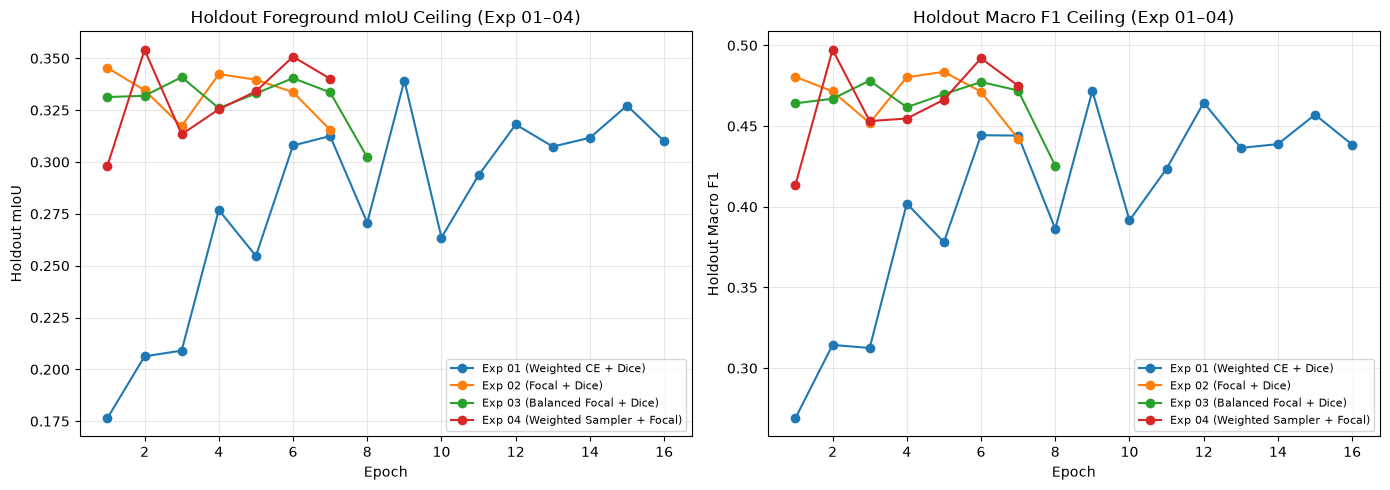

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for name, path in BASELINE_CHECKPOINTS.items():
    if not path.exists():
        continue
    hist = torch.load(path, map_location="cpu", weights_only=False).get("history")
    if isinstance(hist, dict):
        epochs = hist.get("epoch", list(range(1, len(hist["hold_miou"]) + 1)))
        miou = hist["hold_miou"]
        f1 = hist["hold_macro_f1"]
    elif isinstance(hist, list) and hist:
        epochs = [h["epoch"] for h in hist]
        miou = [h.get("holdout_miou", h.get("hold_miou")) for h in hist]
        f1 = [h.get("holdout_macro_f1", h.get("hold_macro_f1")) for h in hist]
    else:
        continue
    axes[0].plot(epochs, miou, marker="o", label=name)
    axes[1].plot(epochs, f1, marker="o", label=name)

axes[0].set_title("Holdout Foreground mIoU Ceiling (Exp 01–04)")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Holdout mIoU")
axes[0].grid(alpha=0.3)
axes[0].legend(fontsize=8)

axes[1].set_title("Holdout Macro F1 Ceiling (Exp 01–04)")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Holdout Macro F1")
axes[1].grid(alpha=0.3)
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

## 4. Quantitative Test Performance & Class Collision Diagnosis
Analyzes the recorded test performance and Experiment 03 confusion matrix (`977,654,263` pixels across 933 test tiles), exposing how single-stage background dominance swallows damaged structures.

          Class     IoU  Precision  Recall      F1  Swallowed as Background (%)
0    Background  0.9767     0.9837  0.9928  0.9882                        99.28
1     No Damage  0.5798     0.7758  0.6965  0.7340                        26.15
2  Minor Damage  0.1056     0.2835  0.1441  0.1911                        30.86
3  Major Damage  0.2778     0.5370  0.3654  0.4348                        23.66
4     Destroyed  0.4365     0.6048  0.6106  0.6077                        30.53


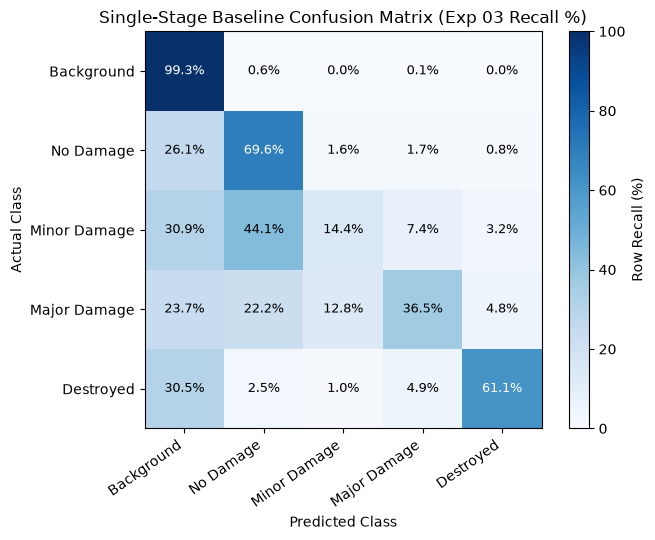

In [4]:
exp03_cm = np.array([
    [913805146,  5428210,  273658,  473472,  446010],
    [ 11472071, 30558518,  717081,  766413,  363309],
    [  1465264,  2094574,  684142,  352596,  152021],
    [  1308930,  1230630,  707115, 2020963,  263648],
    [   937536,    76768,   31101,  150276, 1874811]
], dtype=np.float64)

class_names = ["Background", "No Damage", "Minor Damage", "Major Damage", "Destroyed"]
row_sums = exp03_cm.sum(axis=1, keepdims=True)
norm_cm = (exp03_cm / row_sums) * 100

tp = np.diag(exp03_cm)
fp = exp03_cm.sum(axis=0) - tp
fn = exp03_cm.sum(axis=1) - tp
prec = tp / (tp + fp)
rec = tp / (tp + fn)
f1 = 2 * prec * rec / (prec + rec)
iou = tp / (tp + fp + fn)
swallowed_pct = (exp03_cm[:, 0] / exp03_cm.sum(axis=1)) * 100

diag_df = pd.DataFrame({
    "Class": class_names,
    "IoU": np.round(iou, 4),
    "Precision": np.round(prec, 4),
    "Recall": np.round(rec, 4),
    "F1": np.round(f1, 4),
    "Swallowed as Background (%)": np.round(swallowed_pct, 2)
})
display(diag_df)

fig, ax = plt.subplots(figsize=(7, 5.5))
im = ax.imshow(norm_cm, cmap="Blues", vmin=0, vmax=100)
ax.set_xticks(range(5))
ax.set_yticks(range(5))
ax.set_xticklabels(class_names, rotation=35, ha="right")
ax.set_yticklabels(class_names)
for i in range(5):
    for j in range(5):
        val = norm_cm[i, j]
        ax.text(j, i, f"{val:.1f}%", ha="center", va="center", color="white" if val > 50 else "black", fontsize=9)
ax.set_title("Single-Stage Baseline Confusion Matrix (Exp 03 Recall %)")
ax.set_xlabel("Predicted Class")
ax.set_ylabel("Actual Class")
fig.colorbar(im, ax=ax, label="Row Recall (%)")
plt.tight_layout()
plt.show()

# 5. Baseline Experiment Retrospective & Transition to Dual-Head Architecture

Across Experiments 01–04, the single-stage 5-class `SiameseUNet` plateaued early:
- **Exp 01 (Weighted CE + Dice):** Test mIoU `0.3356` | Macro F1 `0.4694` | Minor Damage F1 `0.1008` (Recall `6.32%`).
- **Exp 02 (Focal + Dice):** Test mIoU `0.3509` | Macro F1 `0.4898` | Minor Damage IoU `0.1041`.
- **Exp 03 (Balanced Focal + Dice):** Over **15.1 million building pixels** (including `30.5%` of all destroyed pixels and `30.9%` of minor-damage pixels) were misclassified as background (`0`).
- **Exp 04 (Weighted Sampler):** Peak Holdout mIoU stalled at `0.3541` (`0.4973` Macro F1) before early stopping at Epoch 7.

### Root Causes Diagnosed:
1. **Single-Stage Class Collision:** Background makes up 94.1% of all pixels, and post-disaster rubble visually resembles bare earth.
2. **Unused Pre-Disaster Building Masks:** Pre-disaster footprints provide sharp geometric building outlines independent of rubble.
3. **Full-Resolution VRAM Bottleneck:** 1024×1024 input tensors forced `batch_size = 1` on 4GB VRAM (~40–70 min/epoch).
4. **Uncalibrated `[0, 1]` Scaling:** Pretrained ResNet encoders expect ImageNet mean/std normalization.

### Transition to Notebook 05 (`DualHeadSiameseUNet`):
To resolve every bottleneck above, [`05_model_training.ipynb`](file:///d:/ML_Project/notebooks/05_model_training.ipynb) introduces the **Dual-Head Siamese U-Net** combining decoupled building localization (`Head 1`), building-masked 4-class damage classification (`Head 2`), guided 512×512 building sampling (`batch_size = 4`), and standardized ImageNet normalization.